# Решение задачи Lid-Driven Cavity с помощью Physics-Informed Neural Networks (PINN)

## Цель работы
Решить стационарную задачу о течении в квадратной каверне с движущейся верхней крышкой (Re = 100) с использованием PINN.

## Постановка задачи
Рассматривается двумерная область \($\Omega$ = [0,1] $\times$ [0,1]\).
- Верхняя стенка (\(y=1\)): \(u = 1, v = 0\) (крышка движется вправо).
- Остальные стенки: \(u = 0, v = 0\) (условие прилипания).

Уравнения Навье-Стокса для стационарного течения несжимаемой жидкости:

$
u \frac{\partial u}{\partial x} + v \frac{\partial u}{\partial y} = -\frac{\partial p}{\partial x} + \frac{1}{Re}\left(\frac{\partial^2 u}{\partial x^2} + \frac{\partial^2 u}{\partial y^2}\right)$

$u \frac{\partial v}{\partial x} + v \frac{\partial v}{\partial y} = -\frac{\partial p}{\partial y} + \frac{1}{Re}\left(\frac{\partial^2 v}{\partial x^2} + \frac{\partial^2 v}{\partial y^2}\right)
$

$\frac{\partial u}{\partial x} + \frac{\partial v}{\partial y} = 0$

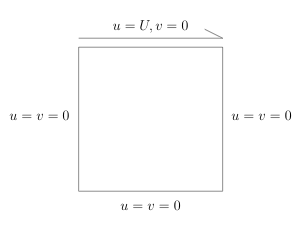
## Метод
Ищем решение c помощью нейросети $f_\theta(x,y) \to (u,v,p) $. Функция потерь состоит из:
1. **PDE-Loss**: невязка уравнений Навье-Стокса в случайных точках внутри области.
2. **BC-Loss**: ошибка на границах (условия прилипания и скорость крышки).

Обучение ведется только на физике (без данных CFD). Для ускорения сходимости используется комбинация оптимизаторов Adam и L-BFGS.

# Формулировка ψ–ω

## Постановка задачи
Квадратная каверна [0,1]×[0,1], верхняя крышка движется со скоростью u=1, v=0.
Все стенки — условие прилипания.

Завихренность — это **z-компонента ротора скорости**:

$\omega = \frac{\partial v}{\partial x} - \frac{\partial u}{\partial y}$

где (u, v) — компоненты скорости. В 3D:

$\vec{\omega} = \nabla \times \vec{u}$.

## Почему ψ–ω
- Неразрывность выполняется точно:

$u=ψ_y$, $v=−ψ_x$
- Уравнения:
  - Пуассон:
  
  $∇²ψ = −ω$
  - Перенос завихренности:
  
  $u·ω_x + v·ω_y = (1/Re)·∇²ω$
- Граничные условия:
  - $ψ = 0$ на всех стенках
  - $ω = −ψ_yy$ на горизонтальных стенках,
  
  $ω = −ψ_xx$ на вертикальных
  - $u = ψ_y = 1$ на верхней крышке

In [ ]:
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.manual_seed(42); np.random.seed(42)
print(f"Using device: {device}")

## Этап 1: Нейросеть с двумя выходами (ψ, ω)

**Задание**: реализуйте класс `PINN_PsiOmega`. Требования:
- Вход: x, y (по 1 числу каждый)
- Внутри: нормализуйте входы как `2*x − 1` и `2*y − 1` (диапазон [−1, 1])
- Активация: `Tanh`
- Выход: два числа — `psi` и `omega`
- Инициализация весов: Xavier normal, bias = 0

In [ ]:
class PINN_PsiOmega(nn.Module):
    def __init__(self, layers=[2, 64, 64, 64, 64, 2]):
        super().__init__()
        self.activation = nn.Tanh()
        self.layers = nn.ModuleList()
        # TODO: создайте Linear-слои по списку layers
        for i in range(len(layers) - 1):
            self.layers.append(nn.Linear(layers[i], layers[i+1]))
        # TODO: инициализация Xavier normal + zero bias
        for m in self.layers:
            nn.init.xavier_normal_(m.weight)
            nn.init.zeros_(m.bias)

    def forward(self, x, y):
        # TODO: нормализуйте входы, прогоните через все слои, кроме последнего, с активацией
        # верните psi, omega как два тензора формы (N, 1)
        raise NotImplementedError("Реализуйте forward pass")

In [ ]:
# Тест этапа 1: сеть должна выдавать два выхода формы (N,1), без NaN
_m = PINN_PsiOmega().to(device)
_x = torch.rand(10, 1).to(device); _y = torch.rand(10, 1).to(device)
_psi, _omega = _m(_x, _y)
assert _psi.shape == (10, 1) and _omega.shape == (10, 1), "Неверная форма выхода"
assert torch.isfinite(_psi).all() and torch.isfinite(_omega).all(), "NaN в выходе"
print("Этап 1 пройден")

model = PINN_PsiOmega().to(device)

## Этап 2: Точки коллокации и граничные точки

**Задание**:
1. `sample_interior(n)` — `n` случайных точек внутри [0,1]².
2. `sample_boundary(n_per_wall)` — по `n_per_wall` точек на каждой из 4 стенок, вернуть 4 пары (x,y).

**Подсказка**: для стенок фиксируйте одну координату (0 или 1) и сэмплируйте другую.

In [ ]:
def sample_interior(n_points):
    """n_points случайных точек внутри [0,1]^2. Возвращает (x, y) на device."""
    # TODO: torch.rand, перенести на device
    raise NotImplementedError

def sample_boundary(n_per_wall):
    """
    Точки на 4 стенках. Возвращает кортеж из 4 пар:
    (bottom, top, left, right), каждая пара — (x, y).
    bottom: y=0, top: y=1, left: x=0, right: x=1.
    """
    # TODO
    raise NotImplementedError

In [ ]:
x_int, y_int = sample_interior(500)
assert x_int.shape == (500,1) and y_int.shape == (500,1)
assert (x_int >= 0).all() and (x_int <= 1).all()
assert (y_int >= 0).all() and (y_int <= 1).all()

b, t, l, r = sample_boundary(50)
assert (b[1] == 0).all(), "bottom должен иметь y=0"
assert (t[1] == 1).all(), "top должен иметь y=1"
assert (l[0] == 0).all(), "left должен иметь x=0"
assert (r[0] == 1).all(), "right должен иметь x=1"
print("Этап 2 пройден")

interior_pts = sample_interior(5000)
boundary_pts = sample_boundary(500)

## Этап 3: Невязки Пуассона и переноса завихренности

Напомним:
- u = ∂ψ/∂y, v = −∂ψ/∂x
- **Пуассон**: ∇²ψ + ω = 0 → невязка `psi_xx + psi_yy + omega`
- **Перенос**: u·ω_x + v·ω_y − (1/Re)·(ω_xx + ω_yy) = 0

**Задание**:
1. Реализуйте `grad(out, inp)` — обёртку над `torch.autograd.grad` с `create_graph=True`.
2. Реализуйте `compute_residuals(model, x, y, Re)`, возвращающую `(res_poisson, res_transport, u, v, psi, omega)`.

**Важно**: перед вызовом модели вызовите `.requires_grad_(True)` на x, y.

In [ ]:
def grad(output, inp):
    """Частная производная output по inp (с сохранением графа)."""
    # TODO
    raise NotImplementedError

def compute_residuals(model, x, y, Re=100.0):
    """
    Возвращает (res_poisson, res_transport, u, v, psi, omega).
    res_poisson   = psi_xx + psi_yy + omega
    res_transport = u*omega_x + v*omega_y - (1/Re)*(omega_xx + omega_yy)
    """
    # TODO: requires_grad_, forward, все нужные производные, собрать невязки
    raise NotImplementedError

In [ ]:
# Тест: невязки должны быть тензорами конечных значений, той же формы что и вход
x_t = torch.rand(20, 1).to(device)
y_t = torch.rand(20, 1).to(device)
r_p, r_t, u_, v_, psi_, om_ = compute_residuals(model, x_t, y_t, Re=100.0)
assert r_p.shape == (20, 1) and r_t.shape == (20, 1)
assert torch.isfinite(r_p).all() and torch.isfinite(r_t).all()
# Проверка связи u,v с psi: численно сравним u с psi_y на малом шаге
eps = 1e-3
psi_p, _ = model(x_t, y_t + eps)
psi_m, _ = model(x_t, y_t - eps)
u_num = (psi_p - psi_m) / (2 * eps)
assert torch.allclose(u_, u_num, atol=1e-2), "u = psi_y не выполняется"
print("Этап 3 пройден")

## Этап 4: Лоссы

Функция потерь = `loss_pde + w_bc * loss_bc`, где:
- `loss_pde = mean(res_poisson²) + mean(res_transport²)`
- `loss_bc` объединяет:
  1. **ψ = 0** на всех 4 стенках
  2. **Условие Тома**: на горизонтальных стенках `ω + ψ_yy = 0`, на вертикальных `ω + ψ_xx = 0`
  3. **Крышка**: `u = ψ_y = 1` при y=1

**Задание**: реализуйте `loss_psi_omega(model, interior_pts, boundary_pts, Re, w_bc)`,
возвращающую `(loss_pde, loss_bc)`.

**Подсказка**: для условия Тома создайте копии координат стенок с `requires_grad_(True)`,
затем через `grad` возьмите вторую производную.

In [ ]:
def loss_psi_omega(model, interior_pts, boundary_pts, Re=100.0, w_bc=10.0):
    x_int, y_int = interior_pts
    (x_b, y_b), (x_t, y_t), (x_l, y_l), (x_r, y_r) = boundary_pts

    # ============ PDE loss ============
    # TODO: вызовите compute_residuals, соберите loss_pde
    raise NotImplementedError("PDE loss")

    # ============ BC по ψ: ψ=0 на всех стенках ============
    # TODO: для каждой стенки посчитайте psi и добавьте mean(psi**2)
    raise NotImplementedError("psi BC")

    # ============ BC по ω (условие Тома) ============
    # Для горизонтальных стенок (bottom, top): omega + psi_yy = 0
    # Для вертикальных (left, right):        omega + psi_xx = 0
    # TODO
    raise NotImplementedError("Tomas BC")

    # ============ Условие на крышке: u = psi_y = 1 при y=1 ============
    # TODO
    raise NotImplementedError("lid BC")

    # loss_bc = w_bc * (все члены BC выше)
    # return loss_pde, loss_bc

In [ ]:
lp, lb = loss_psi_omega(model, interior_pts, boundary_pts, Re=100.0)
assert lp.dim() == 0 and lb.dim() == 0, "Лоссы должны быть скалярами"
assert torch.isfinite(lp) and torch.isfinite(lb)

lp.backward(retain_graph=True); lb.backward(retain_graph=True)
any_grad = any(p.grad is not None for p in model.parameters())
assert any_grad, "Градиенты не доходят до параметров"
model.zero_grad()
print("Этап 4 пройден")

## Этап 5: Цикл обучения

Двухэтапная схема:
1. **Adam** — 5000 итераций, lr=1e-3, для грубого спуска.
2. **L-BFGS** — 2000 итераций, для точной доводки.

**Задание**: заполните циклы. Логируйте `loss_pde` и `loss_bc` каждые 1000 эпох Adam.

In [ ]:
optimizer_adam = torch.optim.Adam(model.parameters(), lr=1e-3)
loss_history = []

for epoch in tqdm(range(5000), desc="Adam"):
    # TODO: zero_grad → loss → backward → step → логирование
    raise NotImplementedError("Цикл Adam")

# --- L-BFGS ---
optimizer_lbfgs = torch.optim.LBFGS(model.parameters(), lr=0.5, max_iter=2000,
                                    history_size=50, line_search_fn="strong_wolfe")
def closure():
    # TODO: zero_grad → loss → backward → return loss
    raise NotImplementedError("closure для LBFGS")

optimizer_lbfgs.step(closure)
print("Обучение завершено")

In [ ]:
plt.figure(figsize=(7, 4))
plt.semilogy(loss_history)
plt.xlabel("Adam epoch"); plt.ylabel("total loss"); plt.grid(True, alpha=0.3)
plt.title("Сходимость обучения")
plt.show()
# Ожидание: лосс упал хотя бы на 2 порядка. Иначе — увеличьте эпохи или проверьте BC.

## Этап 6: Поля u, v, ψ, ω

**Задание**: на сетке 100×100 постройте контурные графики:
- ψ (функция тока), ω (завихренность)
- u = ψ_y, v = −ψ_x

**Подсказка**: для производных используйте ту же обёртку `grad`, предварительно
сделав `xf.requires_grad_(True)`.

In [ ]:
N = 100
xg = torch.linspace(0, 1, N); yg = torch.linspace(0, 1, N)
X, Y = torch.meshgrid(xg, yg, indexing='ij')
xf = X.reshape(-1,1).to(device).requires_grad_(True)
yf = Y.reshape(-1,1).to(device).requires_grad_(True)

# TODO: psi, omega = model(xf, yf); u = grad(psi, yf); v = -grad(psi, xf)
raise NotImplementedError("Поля u,v,psi,omega")

In [ ]:
# Проверка: u на верхней крышке ≈ 1, u на нижней ≈ 0
idx_top = (Y.reshape(-1) > 0.99).nonzero().squeeze()
idx_bot = (Y.reshape(-1) < 0.01).nonzero().squeeze()
print(f"u(y≈1) mean = {U.flatten()[idx_top].mean():.3f} (ожидается ≈1)")
print(f"u(y≈0) mean = {U.flatten()[idx_bot].mean():.3f} (ожидается ≈0)")
assert abs(U.flatten()[idx_top].mean() - 1) < 0.1, "Крышка не движется с u=1"
print("Этап 6 пройден")

# Визуализация
fig, axes = plt.subplots(2, 2, figsize=(11, 9))
for ax, F, title, cmap in zip(axes.ravel(),
        [U, V, PSI, W],
        ['u = ψ_y', 'v = -ψ_x', 'ψ', 'ω'],
        ['RdBu_r', 'RdBu_r', 'viridis', 'RdBu_r']):
    im = ax.contourf(X.cpu(), Y.cpu(), F, levels=50, cmap=cmap)
    ax.set_title(title); ax.set_aspect('equal'); plt.colorbar(im, ax=ax)
plt.tight_layout(); plt.show()

## Этап 7: Валидация против Ghia et al. (1982)

Эталонный профиль u(y) вдоль вертикальной линии x=0.5 для Re=100:
**Задание**: постройте профиль предсказания и наложите точки Ghia, посчитайте RMSE.
Цель: RMSE ≤ 0.05.

In [ ]:
ghia_y = np.array([1.0000, 0.9766, 0.9688, 0.9609, 0.9531, 0.8516, 0.7344, 0.6172,
                   0.5000, 0.4531, 0.2813, 0.1719, 0.1016, 0.0703, 0.0625, 0.0547, 0.0000])
ghia_u = np.array([1.00000, 0.84123, 0.78871, 0.73722, 0.68717, 0.23151, 0.00332, -0.13641,
                   -0.20581, -0.21090, -0.15662, -0.10150, -0.06434, -0.04775, -0.04192, -0.03717, 0.00000])

# TODO: предсказать u вдоль x=0.5 в точках ghia_y
raise NotImplementedError("Профиль u вдоль x=0.5")

# Визуализация
plt.figure(figsize=(6, 5))
plt.plot(ghia_u, ghia_y, 'ko', label='Ghia et al. (1982)')
plt.plot(u_pred_center, ghia_y, 'b-', label='PINN')
plt.xlabel('u'); plt.ylabel('y'); plt.legend(); plt.grid(alpha=0.3)
plt.gca().invert_yaxis(); plt.show()

rmse = np.sqrt(np.mean((u_pred_center - ghia_u)**2))
print(f"RMSE = {rmse:.4f}  (цель ≤ 0.05)")
assert rmse < 0.05, f"RMSE {rmse:.4f} слишком велик — попробуйте больше эпох / точек / w_bc"
print("Этап 7 пройден")